In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2S

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.utils.class_weight import compute_class_weight

from sklearn.preprocessing import label_binarize

In [2]:

TRAIN_GROUNDTRUTH_PATH = "data/train/ISIC_2019_Training_GroundTruth.csv"
TEST_GROUNDTRUTH_PATH = "ham10000/HAM10000_Test_GroundTruth_Updated.csv"
TEST2_GROUNDTRUTH_PATH = "data/test/ISIC_2019_Test_GroundTruth.csv"


TRAIN_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input"  
TEST_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_images_part_12"  
TEST2_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_Input"  
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20 

LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [4]:
len(os.listdir(TRAIN_IMAGE_DIR))

25333

In [5]:
def read_ds(gnd_path):
    """Read a dataset from CSV file and assign labels correspondingly."""
    gnd = pd.read_csv(gnd_path)
    gnd['y'] = gnd[LABELS].idxmax(axis=1)

    return gnd

def get_image_paths_and_labels(groundtruth, image_dir):
    """Generate image paths and corresponding labels from a groundtruth DataFrame."""
    image_paths = [
        os.path.join(image_dir, row['image'] + '.jpg') 
        for _, row in groundtruth.iterrows()
    ]
    labels = [
        LABELS.index(row['y']) 
        for _, row in groundtruth.iterrows()
    ]
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH) 
test_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH) 
test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)
train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
test_paths_2, test_labels_2 = get_image_paths_and_labels(test_groundtruth_2, TEST2_IMAGE_DIR)

In [4]:
# Image preprocessing function
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE[0], IMG_SIZE[1]])
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

# Data Augmentation

In [5]:
# Apply augmentation
def preprocess_and_augment(file_path, label):
    image = tf.io.read_file(file_path)
    image = tf.image.decode_jpeg(image, 
                                 channels=3)
    image = tf.image.resize(image, [IMG_SIZE[0], IMG_SIZE[1]])
    image = tf.keras.applications.efficientnet.preprocess_input(image)
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
    image = tf.image.random_hue(image, max_delta=0.1)
    return image, label

In [6]:
shuffle_size = 512
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset\
    .map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(512)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset_2 = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test_dataset_2 = test_dataset_2\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

2025-03-06 15:15:54.130445: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-03-06 15:15:54.130481: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-03-06 15:15:54.130484: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
I0000 00:00:1741266954.130960 3147537 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1741266954.131366 3147537 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


# Model

In [9]:
base_model = EfficientNetV2S(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(512, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.BatchNormalization()(x)

outputs = layers.Dense(len(LABELS), activation="softmax")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"] 
)

In [11]:
model_path = "model_checkpoint.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="accuracy",
    mode="max",
    save_best_only=True
)

# if os.path.exists(model_path):
#     model = tf.keras.models.load_model(model_path)

early_stop = tf.keras.callbacks.EarlyStopping(
    restore_best_weights=True,
    monitor="val_loss",
    patience=5,  
)

In [49]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb5 (Functional)     │ (None, 15, 15, 2048)   │    28,513,527 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         4,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,568,767 (112.80 MB)

 Trainable params: 1,054,216 (4.02 MB)

 Non-trainable params: 28,514,551 (108.77 MB)

In [50]:
# Imbalance in the dataset
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

# Training & Saving the Model

In [ ]:
# Train the model
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight={i: weight for i, weight in enumerate(class_weights)},
    callbacks=[checkpoint, early_stop]
)

Epoch 1/20
 27/792 ━━━━━━━━━━━━━━━━━━━━ 4:24 346ms/step - accuracy: 0.1151 - loss: 0.9774

KeyboardInterrupt: 

In [ ]:
# Save the final model in h5 format
model.save("final_model.h5")

In [12]:
model = models.load_model('efficientnetv2-s.keras')

In [54]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb5 (Functional)     │ (None, 15, 15, 2048)   │    28,513,527 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │         4,104 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,748,553 (216.48 MB)

 Trainable params: 27,181,832 (103.69 MB)

 Non-trainable params: 2,384,887 (9.10 MB)

 Optimizer params: 27,181,834 (103.69 MB)

### HAM10000

In [13]:
# HAM10000
test_loss, test_accuracy = model.evaluate(test_dataset)
print(f"HAM10000 Test Accuracy: {test_accuracy}")
print(f"HAM10000 Test Loss: {test_loss}")

2025-03-06 15:17:05.136423: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


313/313 ━━━━━━━━━━━━━━━━━━━━ 111s 314ms/step - accuracy: 0.4620 - loss: 1.4153
HAM10000 Test Accuracy: 0.6258612275123596
HAM10000 Test Loss: 1.1008267402648926


In [14]:
y_true = np.concatenate([y for _, y in test_dataset], axis=0)
y_pred = model.predict(test_dataset)
y_pred = np.argmax(y_pred, axis=1)

2025-03-06 15:19:03.446376: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


313/313 ━━━━━━━━━━━━━━━━━━━━ 112s 329ms/step


In [15]:
score_report = classification_report(y_true, y_pred, target_names=[LABELS[i] for i in range(8)], zero_division=0)
print(score_report)

              precision    recall  f1-score   support

         MEL       0.39      0.32      0.35      1113
          NV       0.89      0.77      0.83      6705
         BCC       0.35      0.49      0.41       514
          AK       0.17      0.33      0.23       327
         BKL       0.54      0.14      0.22      1099
          DF       0.09      0.74      0.17       115
        VASC       0.20      0.93      0.33       142
         SCC       0.00      0.00      0.00         0

    accuracy                           0.63     10015
   macro avg       0.33      0.47      0.32     10015
weighted avg       0.73      0.63      0.65     10015



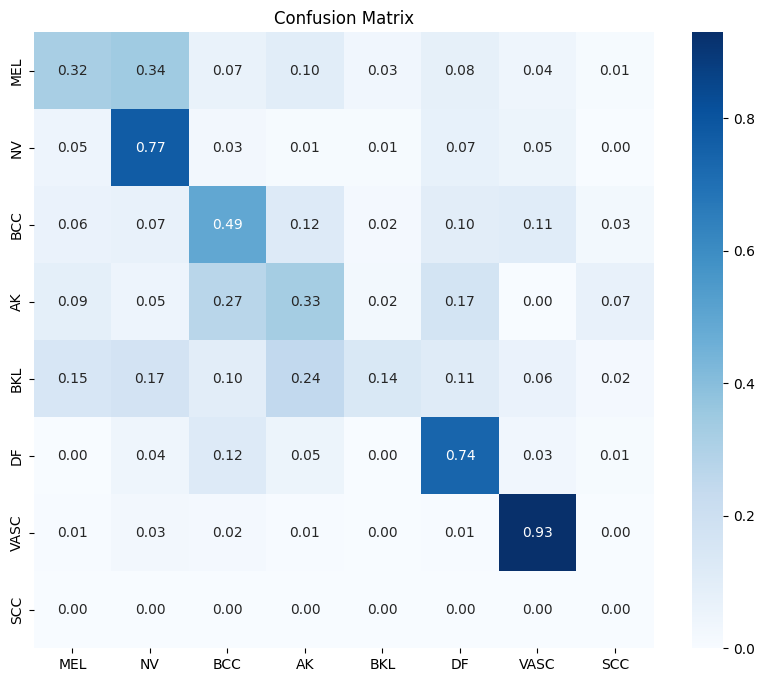

In [16]:
conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

### ISIC 2019

In [17]:
# ISIC 2019
test_loss, test_accuracy = model.evaluate(test_dataset_2)
print(f"HAM10000 Test Accuracy: {test_accuracy}")
print(f"HAM10000 Test Loss: {test_loss}")

258/258 ━━━━━━━━━━━━━━━━━━━━ 91s 351ms/step - accuracy: 0.4698 - loss: 1.6005
HAM10000 Test Accuracy: 0.38722991943359375
HAM10000 Test Loss: 1.9088075160980225


In [18]:
y2_true = np.concatenate([y for _, y in test_dataset_2], axis=0)
y2_pred = model.predict(test_dataset_2)
y2_pred = np.argmax(y2_pred, axis=1)

2025-03-06 15:22:39.786614: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


258/258 ━━━━━━━━━━━━━━━━━━━━ 91s 350ms/step


In [19]:
score_report = classification_report(y2_true, 
                                     y2_pred, 
                                     target_names=[LABELS[i] for i in range(8)])
print(score_report)

              precision    recall  f1-score   support

         MEL       0.58      0.25      0.35      3374
          NV       0.80      0.62      0.70      2495
         BCC       0.29      0.41      0.34       975
          AK       0.14      0.47      0.22       374
         BKL       0.26      0.10      0.14       660
          DF       0.09      0.56      0.16        91
        VASC       0.06      0.43      0.10       104
         SCC       0.10      0.41      0.16       165

    accuracy                           0.39      8238
   macro avg       0.29      0.41      0.27      8238
weighted avg       0.55      0.39      0.42      8238



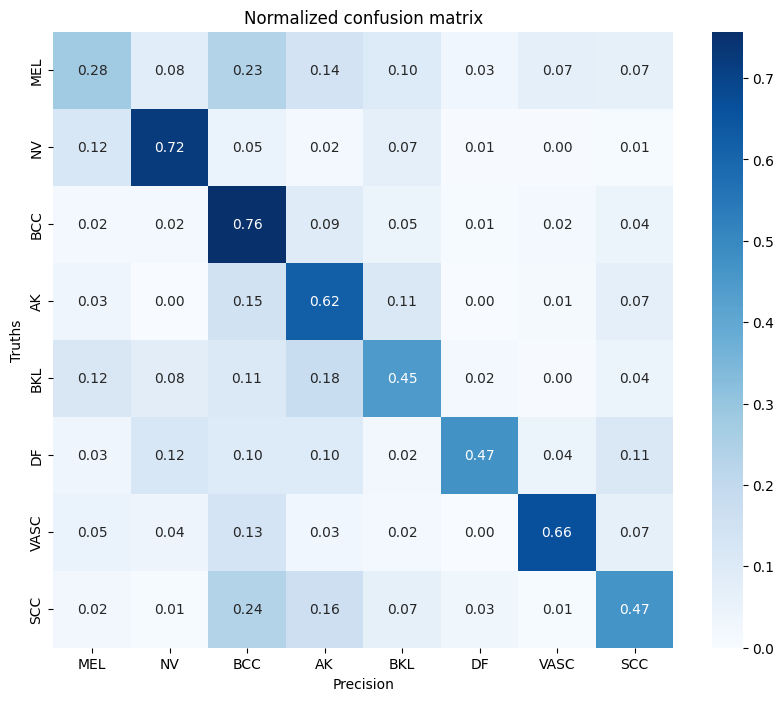

In [ ]:
conf_matrix = confusion_matrix(y2_true, 
                               y2_pred, 
                               normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 

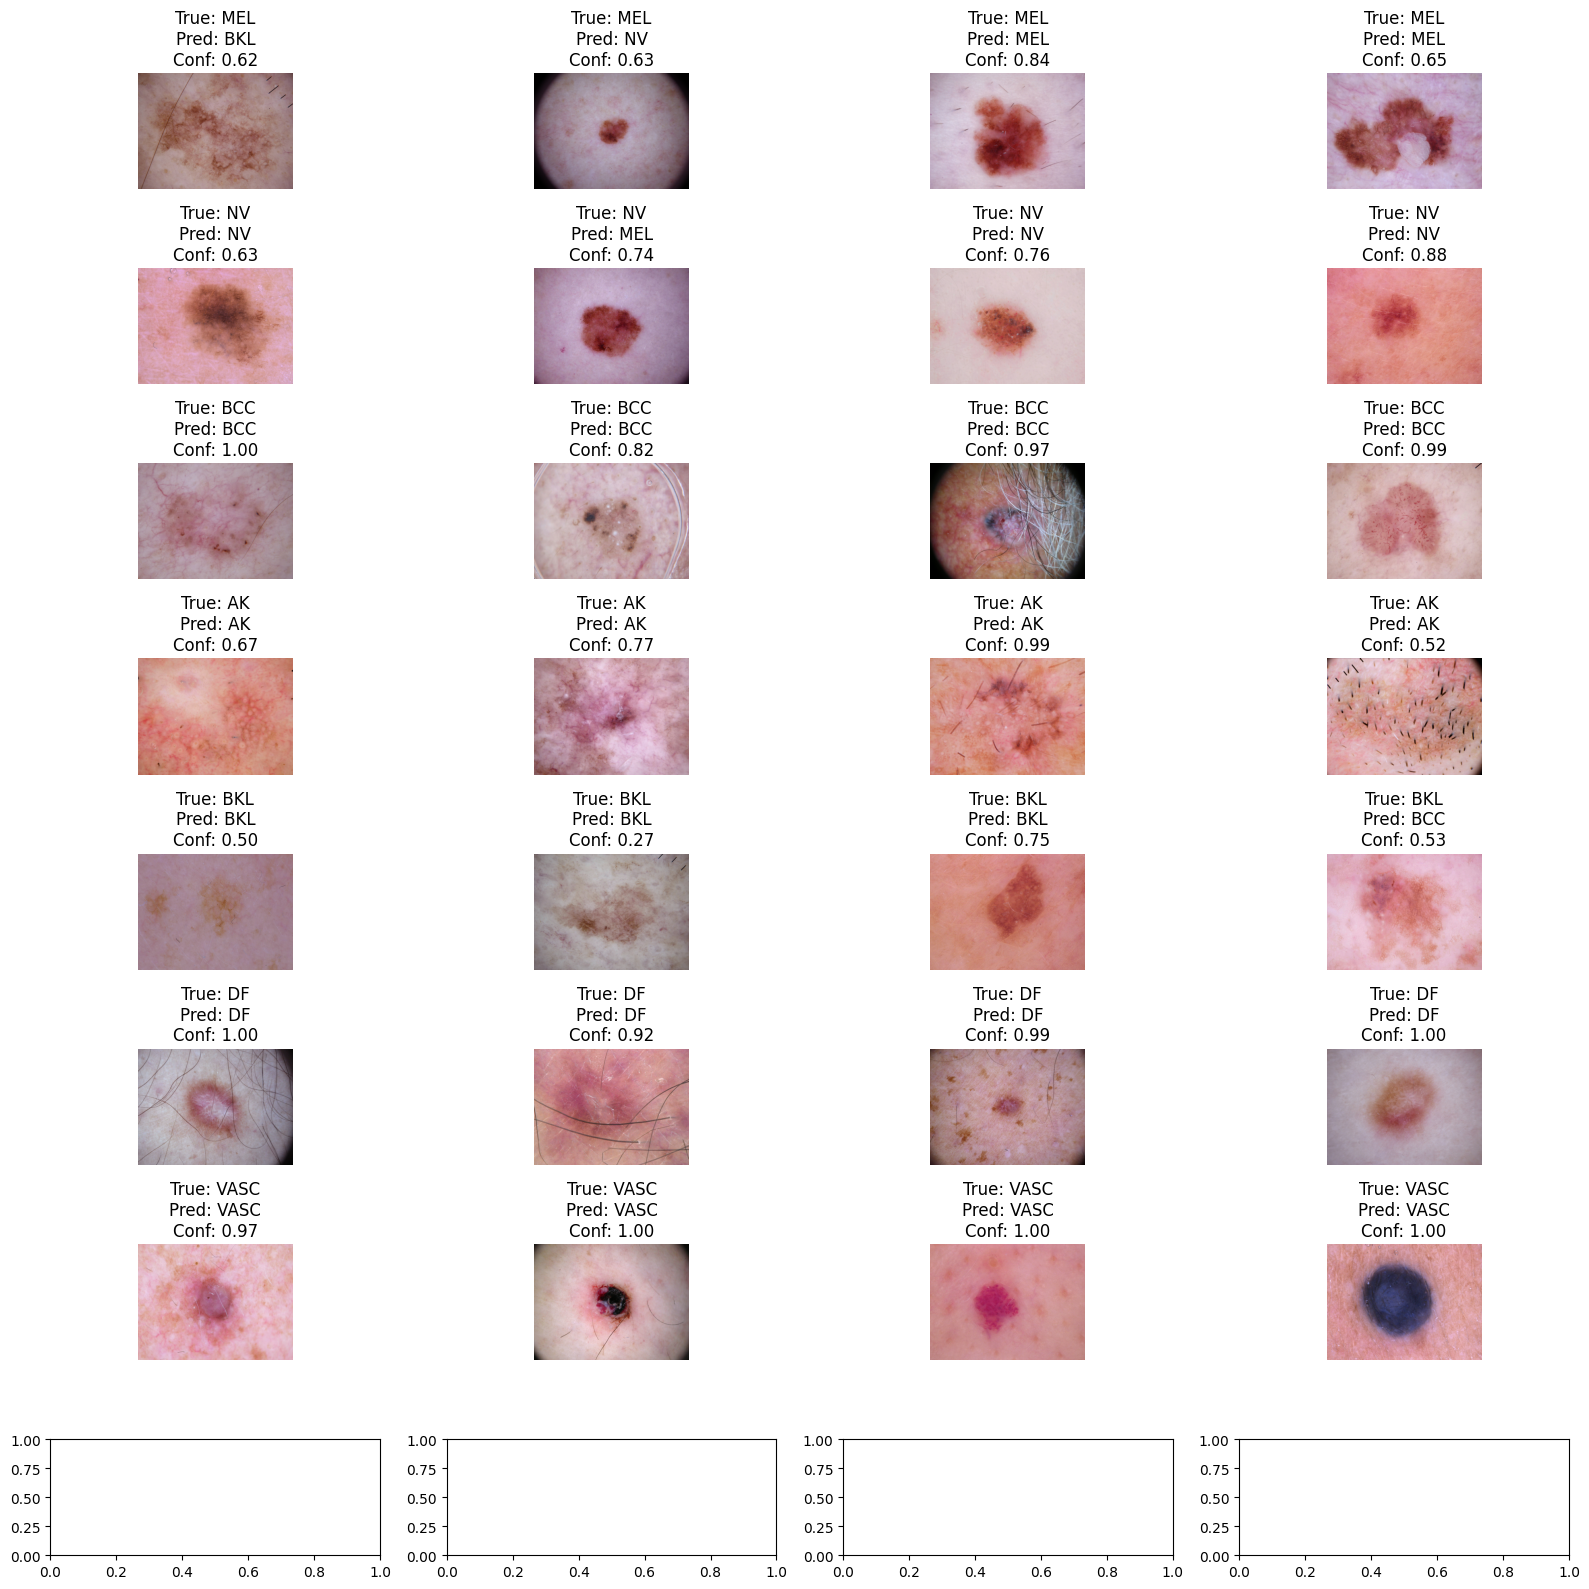

In [ ]:
import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import pandas as pd

LABELS = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

MODEL_PATH = "your_model.h5"
model = tf.keras.models.load_model(MODEL_PATH)

def preprocess_image(img_path, img_size=(224, 224)):  
    img = image.load_img(img_path, target_size=img_size)
    img_array = image.img_to_array(img) / 255.0  
    img_array = np.expand_dims(img_array, axis=0) 
    return img_array

def group_images_by_label(paths, labels):
    grouped = {label: [] for label in LABELS}
    for path, label in zip(paths, labels):
        grouped[LABELS[label]].append(path)
    return grouped

grouped_test_1 = group_images_by_label(test_paths, test_labels)
grouped_test_2 = group_images_by_label(test_paths_2, test_labels_2)

selected_images_1 = {label: random.choice(paths) for label, paths in grouped_test_1.items()}
selected_images_2 = {label: random.choice(paths) for label, paths in grouped_test_2.items()}

fig, axes = plt.subplots(2, len(LABELS), figsize=(20, 10))

for idx, label in enumerate(LABELS):
    img_1_path = selected_images_1[label]
    img_2_path = selected_images_2[label]

    img_1 = preprocess_image(img_1_path)
    img_2 = preprocess_image(img_2_path)
    
    pred_1 = model.predict(img_1)
    pred_2 = model.predict(img_2)
    
    label_1 = LABELS[np.argmax(pred_1)]
    label_2 = LABELS[np.argmax(pred_2)]

    axes[0, idx].imshow(image.load_img(img_1_path))
    axes[0, idx].set_title(f"Dataset 1\nPred: {label_1}")
    axes[0, idx].axis('off')
    
    axes[1, idx].imshow(image.load_img(img_2_path))
    axes[1, idx].set_title(f"Dataset 2\nPred: {label_2}")
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
memory_info = tf.config.experimental.get_memory_info('GPU:0')

print("Memory Usage (Bytes):", memory_info)